# Detección de EPOC a partir de la tos con Deep Learning: análisis de viabilidad
**Dataset:** Cough-COPD (CC), Zenodo · 853 grabaciones (221 EPOC, 632 sanos)

**Contenido**
| Etapa | Secciones |
|---|---|
| Obtención de datos | 1. Instalación · 2. Descarga · 3. Inventario |
| **Etiquetado** | 4. Etiquetado de los audios |
| **Data: sanos / EPOC** | 5. Distribución de la data · 6. Calidad del audio |
| Validación del dataset | 7. Chequeo de atajos · 8. Línea base |
| Preprocesamiento | 9. Detección de toses |
| **Balanceo** | 10. Balanceo de clases (1000 sanos / 1000 EPOC) |
| Modelado | 11. Limpieza y control · 12. Modelo final · 13. Métricas de tamizaje |
| Cierre | 14. Resumen y conclusiones |

Todas las evaluaciones usan **validación cruzada estratificada y agrupada por participante** (5-fold × 5 repeticiones).

**Cómo usar:** Entorno de ejecución › Ejecutar todo (≈ 20–25 min).

## 1. Instalación

In [ ]:
!apt-get -qq install -y unrar > /dev/null
!pip -q install librosa soundfile tensorflow_hub scikit-learn pandas matplotlib tqdm

## 2. Descarga y verificación (Zenodo, v1)

In [ ]:
import os, hashlib
os.makedirs('/content/cc/data', exist_ok=True)
URL = "https://zenodo.org/records/10209837/files/COPD-Cough%20(CC).rar?download=1"
RAR = "/content/cc/cc.rar"
if not os.path.exists(RAR):
    !wget -q -O {RAR} "{URL}"

h = hashlib.md5()
with open(RAR, 'rb') as f:
    for chunk in iter(lambda: f.read(1 << 20), b''):
        h.update(chunk)
print("md5:", h.hexdigest(), "| coincide:", h.hexdigest() == "bad6d34cc5e07699d2878aee61d1ca05")
!unrar x -o+ -inul "{RAR}" /content/cc/data/ || 7z x -y -o/content/cc/data "{RAR}"

md5: bad6d34cc5e07699d2878aee61d1ca05 | coincide: True


## 3. Inventario de archivos

In [ ]:
import numpy as np, pandas as pd
from pathlib import Path

root = Path('/content/cc/data')
AUDIO_EXT = {'.wav', '.mp3', '.flac', '.m4a', '.ogg', '.aac'}
files = [p for p in root.rglob('*') if p.is_file()]
print("Extensiones:\n", pd.Series([p.suffix.lower() for p in files]).value_counts(), "\n")

audio = sorted(p for p in files if p.suffix.lower() in AUDIO_EXT)
print("Archivos de audio:", len(audio), "\n")
print("Audios por carpeta:\n", pd.Series([str(p.parent.relative_to(root)) for p in audio]).value_counts(), "\n")
print("Ejemplos de nombres:")
for p in audio[:12]:
    print("  ", p.relative_to(root))
non_audio = [p for p in files if p.suffix.lower() not in AUDIO_EXT]
print("\nOtros archivos (metadatos, csv, txt):", [str(p.relative_to(root)) for p in non_audio][:20])

Extensiones:
 .wav    853
Name: count, dtype: int64 

Archivos de audio: 853 

Audios por carpeta:
 COPD-Cough (CC)/COPD/COPDi-11-003    15
COPD-Cough (CC)/COPD/COPDi-11-004    12
COPD-Cough (CC)/COPD/COPDi-08-005     5
COPD-Cough (CC)/COPD/COPDi-08-006     5
COPD-Cough (CC)/COPD/05-18-07         5
                                     ..
COPD-Cough (CC)/COPD/COPD-w10         1
COPD-Cough (CC)/COPD/k24              1
COPD-Cough (CC)/COPD/COPDi-11-011     1
COPD-Cough (CC)/COPD/COPDi-11-010     1
COPD-Cough (CC)/COPD/08-25-04         1
Name: count, Length: 289, dtype: int64 

Ejemplos de nombres:
   COPD-Cough (CC)/COPD/05-18-01/1684392787680-剪辑-20230628094734.wav
   COPD-Cough (CC)/COPD/05-18-02/1684394281269-剪辑-20230628095742.wav
   COPD-Cough (CC)/COPD/05-18-02/1684394297344-剪辑-20230628095909.wav
   COPD-Cough (CC)/COPD/05-18-02/1684394311068-剪辑-20230628100040.wav
   COPD-Cough (CC)/COPD/05-18-03/1684393202182-剪辑-20230628100354.wav
   COPD-Cough (CC)/COPD/05-18-03/1684393223898-剪辑-202

## 4. Etiquetado de los audios
Cada audio se etiqueta según la carpeta del dataset donde se encuentra:
- **1 = EPOC:** audios dentro de la carpeta `COPD`.
- **0 = Sano:** audios dentro de la carpeta de controles sanos.

Además, cada audio recibe un **grupo** (la carpeta que lo contiene, que identifica al participante o sesión). El grupo se usa para que las grabaciones de una misma persona nunca queden repartidas entre entrenamiento y prueba. El conteo esperado según el paper del dataset es **221 EPOC y 632 sanos**.

In [ ]:
tops = list(root.iterdir())
base = tops[0] if (len(tops) == 1 and tops[0].is_dir()) else root

HEALTHY_KEYS = ['healthy', 'normal', 'control', 'health', 'non-copd', 'noncopd']
COPD_KEYS = ['copd']

def infer_label(p):
    s = str(p.relative_to(base)).lower()
    if any(k in s for k in HEALTHY_KEYS):
        return 0
    if any(k in s for k in COPD_KEYS):
        return 1
    return None

df = pd.DataFrame({'path': audio})
df['label'] = df.path.apply(infer_label)
print(df.label.value_counts(dropna=False))
assert df.label.notna().all(), "Hay audios sin etiqueta: ajusta infer_label con los nombres de la sección 3"
df['label'] = df.label.astype(int)
n1, n0 = int((df.label == 1).sum()), int((df.label == 0).sum())
print(f"EPOC={n1} Sanos={n0} (esperado 221 / 632)")
if (n1, n0) != (221, 632):
    print("ATENCION: los conteos no coinciden con el paper. Revisa etiquetas o duplicados antes de seguir.")

df['grupo'] = df.path.apply(lambda p: p.parent.name)
df['rec_id'] = np.arange(len(df))
print("\nGrupos (carpetas) por clase:", df.groupby('label').grupo.nunique().rename({0: 'sano', 1: 'EPOC'}).to_dict())
print("Ejemplos de grupos de sanos:", list(df[df.label == 0].grupo.unique()[:8]))
print("Ejemplos de grupos de EPOC: ", list(df[df.label == 1].grupo.unique()[:8]))

label
0    632
1    221
Name: count, dtype: int64
EPOC=221 Sanos=632 (esperado 221 / 632)

Grupos (carpetas) por clase: {'sano': 211, 'EPOC': 78}
Ejemplos de grupos de sanos: ['06-19-01', '06-19-02', '06-19-03', '06-19-04', '06-19-05', '06-19-06', '06-19-07', '06-19-08']
Ejemplos de grupos de EPOC:  ['05-18-01', '05-18-02', '05-18-03', '05-18-04', '05-18-05', '05-18-07', '05-18-08', '05-18-09']


In [ ]:
# Tabla de etiquetado: una fila por audio
etiquetas = df[['path', 'label', 'grupo']].copy()
etiquetas['archivo'] = etiquetas.path.apply(lambda p: str(p.relative_to(base)))
etiquetas['clase'] = etiquetas.label.map({0: 'Sano', 1: 'EPOC'})
etiquetas = etiquetas[['archivo', 'grupo', 'label', 'clase']]
etiquetas.to_csv('/content/cc/etiquetas.csv', index=False)
print("Etiquetas guardadas en /content/cc/etiquetas.csv\n")
display(etiquetas.groupby('clase').head(3).sort_values('label'))

Etiquetas guardadas en /content/cc/etiquetas.csv



,archivo,grupo,label,clase
221,Healthy/06-19-01/1687158350971.wav,06-19-01,0,Sano
222,Healthy/06-19-01/1687158383620.wav,06-19-01,0,Sano
223,Healthy/06-19-01/1687158395546.wav,06-19-01,0,Sano
0,COPD/05-18-01/1684392787680-剪辑-20230628094734.wav,05-18-01,1,EPOC
2,COPD/05-18-02/1684394297344-剪辑-20230628095909.wav,05-18-02,1,EPOC
1,COPD/05-18-02/1684394281269-剪辑-20230628095742.wav,05-18-02,1,EPOC


## 5. Distribución de la data: sanos vs EPOC
Cuántos audios, participantes y minutos de grabación tiene cada clase. Muestra el **desbalance original** del dataset, que se corrige en la sección 10.

       audios  participantes  minutos  duracion_media_s  % audios
label                                                            
Sano      632            211     76.3               7.2      74.1
EPOC      221             78     29.0               7.9      25.9

Razón de desbalance: 2.9 audios sanos por cada audio EPOC


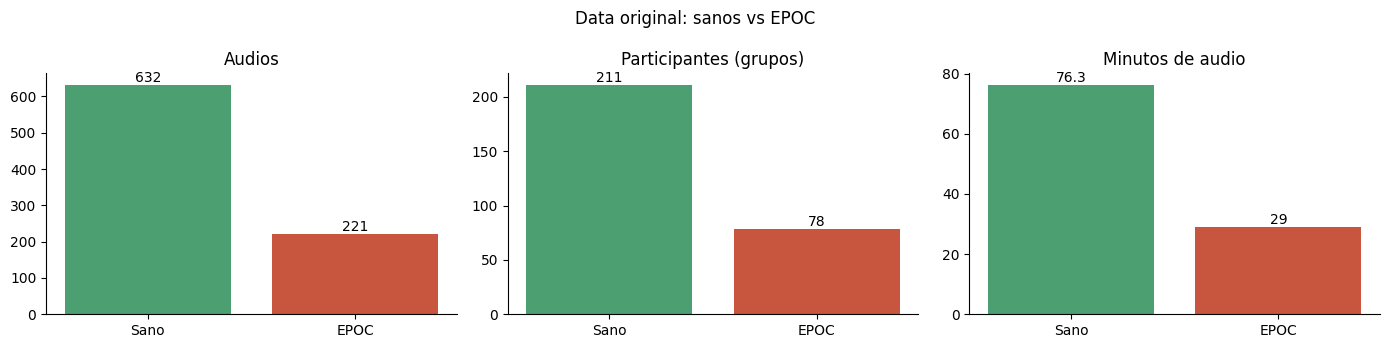

In [ ]:
import soundfile as sf
import matplotlib.pyplot as plt
tmp = df[['path', 'label', 'grupo']].copy()
tmp['dur'] = tmp.path.apply(lambda p: sf.info(str(p)).duration)

resumen = tmp.groupby(tmp.label.map({0: 'Sano', 1: 'EPOC'})).agg(
    audios=('path', 'count'), participantes=('grupo', 'nunique'),
    minutos=('dur', lambda d: round(d.sum() / 60, 1)), duracion_media_s=('dur', lambda d: round(d.mean(), 1)))
resumen['% audios'] = (resumen.audios / resumen.audios.sum() * 100).round(1)
print(resumen.loc[['Sano', 'EPOC']].to_string())
print(f"\nRazón de desbalance: {resumen.loc['Sano','audios'] / resumen.loc['EPOC','audios']:.1f} audios sanos por cada audio EPOC")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
colores = ['#4C9F70', '#C8553D']
for a, col, tit in zip(ax, ['audios', 'participantes', 'minutos'], ['Audios', 'Participantes (grupos)', 'Minutos de audio']):
    v = resumen.loc[['Sano', 'EPOC'], col]
    a.bar(v.index, v.values, color=colores)
    for i, val in enumerate(v.values):
        a.text(i, val, f"{val:g}", ha='center', va='bottom')
    a.set_title(tit); a.spines[['top', 'right']].set_visible(False)
plt.suptitle("Data original: sanos vs EPOC"); plt.tight_layout(); plt.show()

## 6. Calidad del audio por clase

In [ ]:
import librosa, soundfile as sf
from tqdm import tqdm

def stats(p):
    x, sr = librosa.load(str(p), sr=None, mono=True)
    try:
        ch = sf.info(str(p)).channels
    except Exception:
        ch = np.nan
    dur = len(x) / sr
    rms = float(np.sqrt(np.mean(x ** 2)) + 1e-12)
    peak = float(np.max(np.abs(x)) + 1e-12)
    fr = librosa.feature.rms(y=x, frame_length=2048, hop_length=512)[0] + 1e-12
    snr = 20 * np.log10(np.percentile(fr, 90) / np.percentile(fr, 10))      # SNR aproximado por percentiles
    sil = float(np.mean(20 * np.log10(fr / fr.max()) < -40))
    return dict(sr=sr, ch=ch, dur=dur, rms_db=20 * np.log10(rms), peak_db=20 * np.log10(peak),
                snr_db=snr, silence_frac=sil, nan_or_inf=bool(not np.isfinite(x).all()),
                md5=hashlib.md5(open(p, 'rb').read()).hexdigest())

meta_rec = pd.DataFrame([stats(p) for p in tqdm(df.path, desc="Calidad")])
df = pd.concat([df.reset_index(drop=True), meta_rec], axis=1)
df.drop(columns='md5').to_csv('/content/cc/inventario.csv', index=False)

print(df.groupby('label')[['dur', 'rms_db', 'peak_db', 'snr_db', 'silence_frac']].describe().T.round(2))
print("\nFrecuencias de muestreo por clase:\n", pd.crosstab(df.sr, df.label))
print("\nCanales por clase:\n", pd.crosstab(df.ch, df.label))
print("\nAudios de menos de 2 s:", int((df.dur < 2).sum()))
print("Audios con SNR aprox. < 10 dB:", int((df.snr_db < 10).sum()))
print("Archivos con NaN/Inf:", int(df.nan_or_inf.sum()))
print("Archivos idénticos (hash):", int(df.md5.duplicated().sum()))

Calidad: 100%|██████████| 853/853 [00:41<00:00, 20.34it/s]


label                    0       1
dur          count  632.00  221.00
             mean     7.24    7.88
             std      1.75    4.13
             min      3.82    0.86
             25%      6.18    6.21
             50%      6.91    7.20
             75%      7.72    9.02
             max     29.92   36.38
rms_db       count  632.00  221.00
             mean   -25.90  -24.88
             std      4.01    4.30
             min    -40.42  -38.18
             25%    -28.08  -27.56
             50%    -25.44  -25.03
             75%    -23.18  -21.91
             max    -15.93  -14.19
peak_db      count  632.00  221.00
             mean    -2.74   -2.56
             std      2.36    2.07
             min    -13.83  -10.65
             25%     -4.01   -3.56
             50%     -1.93   -2.27
             75%     -0.85   -0.78
             max      0.00    0.00
snr_db       count  632.00  221.00
             mean    29.98   29.86
             std      9.22   15.94
             min    

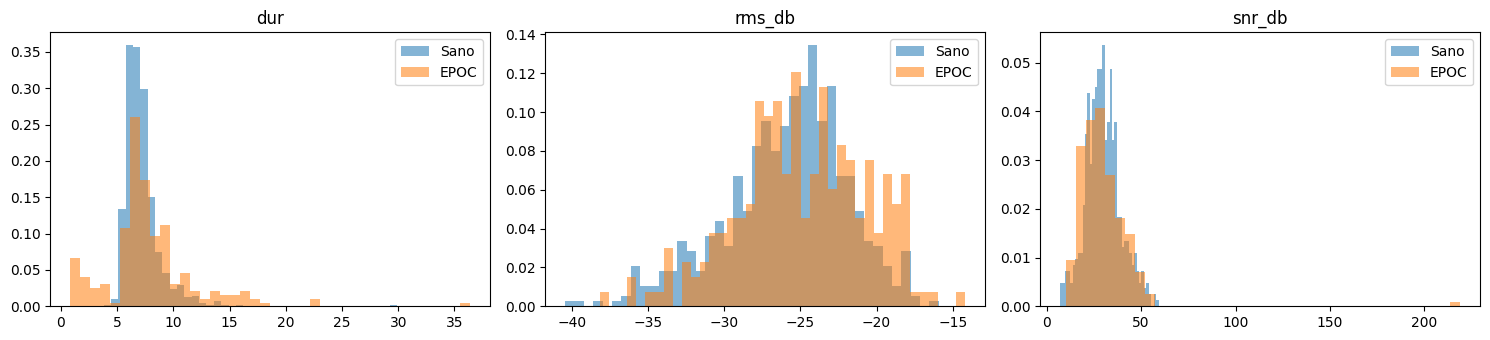

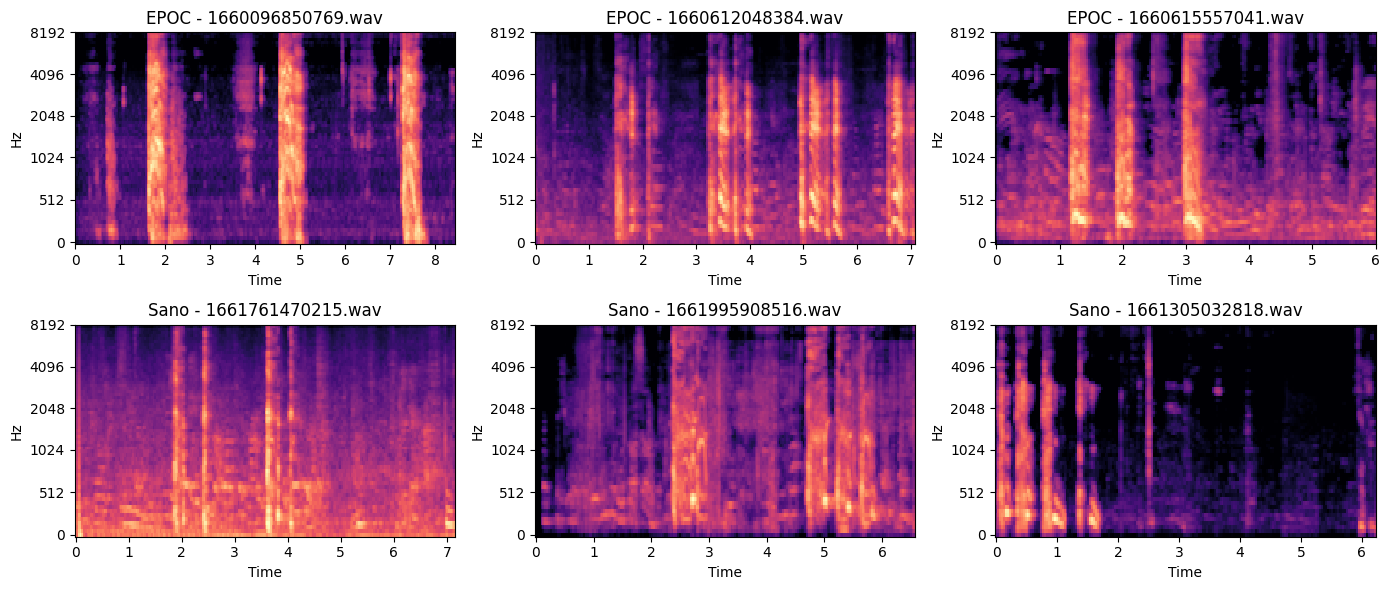

In [ ]:
import matplotlib.pyplot as plt
import librosa.display

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for i, c in enumerate(['dur', 'rms_db', 'snr_db']):
    for l, name in [(0, 'Sano'), (1, 'EPOC')]:
        ax[i].hist(df[df.label == l][c], bins=40, alpha=.55, label=name, density=True)
    ax[i].set_title(c); ax[i].legend()
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 3, figsize=(14, 6))
for r, l in enumerate([1, 0]):
    for k, p in enumerate(df[df.label == l].path.sample(3, random_state=1)):
        x, sr_ = librosa.load(str(p), sr=16000)
        S = librosa.power_to_db(librosa.feature.melspectrogram(y=x, sr=sr_, n_mels=64), ref=np.max)
        librosa.display.specshow(S, sr=sr_, x_axis='time', y_axis='mel', ax=axs[r, k])
        axs[r, k].set_title(('EPOC' if l else 'Sano') + ' - ' + Path(p).name[:25])
plt.tight_layout(); plt.show()

## 7. Funciones de evaluación y chequeo de atajos (grabación completa)
Todas las evaluaciones del notebook usan **validación cruzada estratificada y agrupada por participante** (5-fold, varias repeticiones), con AUC, sensibilidad, especificidad, balanced accuracy y exactitud, más IC95 por bootstrap.

**Chequeo de atajos:** si un modelo que solo ve duración, volumen, SNR y silencios separa EPOC de sano (AUC >> 0.5), el dataset tiene artefactos de grabación y un modelo sobre audio podría estar aprendiendo eso y no la tos.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, balanced_accuracy_score

def evaluar(make_model, X, y, grupos, rec_ids, repeats=5, seed=100):
    """CV agrupada. Devuelve métricas por muestra y por grabación (promedio de sus muestras)."""
    rows, rec0 = [], None
    for rep in range(repeats):
        p = np.zeros(len(y))
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=seed + rep).split(X, y, grupos):
            p[te] = make_model().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
        rec = pd.DataFrame(dict(rec=rec_ids, y=y, p=p)).groupby('rec').agg(y=('y', 'first'), p=('p', 'mean'))
        pred = (rec.p >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(rec.y, pred, labels=[0, 1]).ravel()
        rows.append(dict(auc_muestra=roc_auc_score(y, p), auc_grab=roc_auc_score(rec.y, rec.p),
                         sens=tp / (tp + fn), spec=tn / (tn + fp),
                         bacc=balanced_accuracy_score(rec.y, pred), acc=(tp + tn) / len(rec)))
        rec0 = rec if rep == 0 else rec0
    return pd.DataFrame(rows), rec0

def boot_ci(y, p, n=2000, seed=0):
    rng = np.random.default_rng(seed); v = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) > 1:
            v.append(roc_auc_score(y[i], p[i]))
    return np.percentile(v, [2.5, 97.5])

def tabla(modelos, y, grupos, rec_ids, repeats=5, por_muestra=False):
    filas = []
    for nom, (mk, feats) in modelos.items():
        r_, rec0 = evaluar(mk, feats, y, grupos, rec_ids, repeats)
        lo, hi = boot_ci(rec0.y.values, rec0.p.values)
        fila = dict(modelo=nom)
        if por_muestra:
            fila['AUC_ventana'] = f"{r_.auc_muestra.mean():.3f} ± {r_.auc_muestra.std():.3f}"
        fila.update(AUC_grabacion=f"{r_.auc_grab.mean():.3f} ± {r_.auc_grab.std():.3f}", IC95=f"[{lo:.3f}, {hi:.3f}]",
                    Sens=f"{r_.sens.mean():.3f}", Esp=f"{r_.spec.mean():.3f}",
                    BalAcc=f"{r_.bacc.mean():.3f}", Acc=f"{r_.acc.mean():.3f}")
        filas.append(fila)
    return pd.DataFrame(filas)

# --- Chequeo de atajos a nivel de grabación completa ---
y_rec = df.label.values
g_rec = df.grupo.values
META_COLS = ['sr', 'dur', 'rms_db', 'peak_db', 'snr_db', 'silence_frac']
Xm_rec = df[META_COLS].values.astype(float)

def uni_auc(c):
    a = roc_auc_score(y_rec, df[c].fillna(0))
    return max(a, 1 - a)          # 0.5 = sin información
print("AUC univariado por variable:")
print(pd.Series({c: uni_auc(c) for c in META_COLS}).sort_values(ascending=False).round(3))

rf = RandomForestClassifier(300, class_weight='balanced', min_samples_leaf=3, random_state=0)
r_m, _ = evaluar(lambda: rf, Xm_rec, y_rec, g_rec, df.rec_id.values)
print(f"\nAUC solo con metadatos de grabación: {r_m.auc_grab.mean():.3f} ± {r_m.auc_grab.std():.3f}")
print("-> cercano a 0.50: bien. Mucho mayor (>0.65): hay atajos; hay que recortar/normalizar y reportarlo.")

AUC univariado por variable:
silence_frac    0.585
rms_db          0.563
dur             0.558
snr_db          0.539
peak_db         0.509
sr              0.500
dtype: float64

AUC solo con metadatos de grabación: 0.670 ± 0.011
-> cercano a 0.50: bien. Mucho mayor (>0.65): hay atajos; hay que recortar/normalizar y reportarlo.


## 8. Línea base: embeddings YAMNet por grabación completa
Modelo sobre el audio completo, sin limpiar. Su AUC aparente es alto, pero hay que compararlo con el modelo **solo metadatos** de la sección 6: si se parecen, el modelo está aprovechando las condiciones de grabación y no la tos.

In [ ]:
import tensorflow_hub as hub
yamnet = hub.load('https://tfhub.dev/google/yamnet/1')
vggish = hub.load('https://tfhub.dev/google/vggish/1')

def embed_grabacion(p, max_s=30):
    x, _ = librosa.load(str(p), sr=16000, mono=True)
    x = x[:16000 * max_s]
    x = x / (np.max(np.abs(x)) + 1e-9)
    if len(x) < 16000:
        x = np.pad(x, (0, 16000 - len(x)))
    e = yamnet(x.astype(np.float32))[1].numpy()
    return np.concatenate([e.mean(0), e.std(0)])

X_rec = np.stack([embed_grabacion(p) for p in tqdm(df.path, desc="YAMNet grabaciones")])
np.save('/content/cc/X_yamnet_grabacion.npy', X_rec)

modelos_base = {
    'Mayoritaria (baseline)': (lambda: DummyClassifier(strategy='prior'), X_rec),
    'Solo metadatos (RF)':    (lambda: RandomForestClassifier(300, class_weight='balanced', min_samples_leaf=3, random_state=0), Xm_rec),
    'YAMNet + LogReg':        (lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.05, class_weight='balanced', max_iter=3000)), X_rec),
    'YAMNet + SVM-RBF':       (lambda: make_pipeline(StandardScaler(), SVC(C=1, probability=True, class_weight='balanced', random_state=0)), X_rec),
}
tabla_base = tabla(modelos_base, y_rec, g_rec, df.rec_id.values)
print(tabla_base.to_string(index=False))

YAMNet grabaciones: 100%|██████████| 853/853 [01:26<00:00,  9.87it/s]


                modelo AUC_grabacion           IC95  Sens   Esp BalAcc   Acc
Mayoritaria (baseline) 0.431 ± 0.017 [0.399, 0.485] 0.000 1.000  0.500 0.741
   Solo metadatos (RF) 0.670 ± 0.011 [0.627, 0.712] 0.352 0.903  0.627 0.760
       YAMNet + LogReg 0.686 ± 0.014 [0.622, 0.706] 0.452 0.790  0.621 0.702
      YAMNet + SVM-RBF 0.717 ± 0.009 [0.667, 0.745] 0.253 0.918  0.586 0.746


## 9. Detección de toses por energía

In [ ]:
from scipy.signal import butter, sosfiltfilt

SR = 16000
SOS = butter(4, [80, 4000], btype='band', fs=SR, output='sos')
FR, HP = int(0.025 * SR), int(0.010 * SR)

def cough_segments(path, min_dur=0.10, max_dur=1.5, merge_gap=0.15, k=0.35):
    x, _ = librosa.load(str(path), sr=SR, mono=True)
    x = sosfiltfilt(SOS, x)
    env = librosa.feature.rms(y=x, frame_length=FR, hop_length=HP)[0]
    env = np.convolve(env, np.ones(5) / 5, mode='same')
    base_, top = np.percentile(env, 20), np.percentile(env, 98)
    act = env > base_ + k * (top - base_)              # umbral adaptativo por grabación
    segs, i = [], 0
    while i < len(act):
        if act[i]:
            j = i
            while j < len(act) and act[j]:
                j += 1
            segs.append([i, j]); i = j
        else:
            i += 1
    merged = []
    for s, e in segs:                                   # une picos muy cercanos (misma tos)
        if merged and (s - merged[-1][1]) * HP / SR < merge_gap:
            merged[-1][1] = e
        else:
            merged.append([s, e])
    return [(s * HP / SR, min(e * HP / SR, s * HP / SR + max_dur))
            for s, e in merged if (e - s) * HP / SR >= min_dur]

df['segs'] = [cough_segments(p) for p in tqdm(df.path, desc="Toses")]
df['n_toses'] = df.segs.apply(len)
print(df.groupby('label').n_toses.agg(['sum', 'mean', 'median', 'max']).rename(index={0: 'sano', 1: 'EPOC'}))
print("Grabaciones sin ninguna tos detectada:", int((df.n_toses == 0).sum()))
print("AVISO: conteo aproximado por energía; verifícalo a oído en la sección 10 (balanceo).")

Toses: 100%|██████████| 853/853 [00:19<00:00, 44.26it/s]

        sum      mean  median  max
label                             
sano   2098  3.319620     3.0   12
EPOC    885  4.004525     4.0   18
Grabaciones sin ninguna tos detectada: 4
AVISO: conteo aproximado por energía; verifícalo a oído en la sección 10 (balanceo).


## 10. Balanceo de clases: 1000 sanos / 1000 EPOC
El dataset original está desbalanceado (632 sanos frente a 221 EPOC, casi 3 a 1). Se aplican dos estrategias:

1. **Conjunto balanceado de segmentos:** cada grabación se recorre con ventanas de 1.5 s que avanzan 0.5 s, y se conservan solo las que contienen al menos el 80 % de una tos. Luego se eligen **exactamente 1000 por clase**: primero una ventana de cada grabación, después la segunda, y así sucesivamente, para que ninguna grabación aporte de más. **Todos los segmentos son audio real; no se usan datos sintéticos.**
2. **Pesos por clase** (`class_weight='balanced'`) en todos los modelos, para que la clase minoritaria pese igual durante el entrenamiento.

La división entrenamiento/prueba (80/20) se hace **por participante**, así que una misma persona nunca aparece en ambos lados.

In [ ]:
def normalizar(s):
    s = s - s.mean()
    return (s / (np.max(np.abs(s)) + 1e-9) * 0.9).astype(np.float32)

import shutil
WIN_S, HOP_S, N_OBJ, COB_MIN = 1.5, 0.5, 1000, 0.8     # si faltan ventanas, baja HOP_S a 0.25
W = int(WIN_S * SR)

cand = []
for _, r in df.iterrows():
    starts = np.arange(0, r.dur - WIN_S + 1e-9, HOP_S) if r.dur > WIN_S else [0.0]
    for t in starts:
        if any(min(t + WIN_S, b) - max(t, a) >= COB_MIN * (b - a) for a, b in r.segs):
            cand.append(dict(rec_id=r.rec_id, label=r.label, grupo=r.grupo, path=str(r.path), t0=float(t)))
cand = pd.DataFrame(cand)

def seleccionar(c, n):
    c = c.sample(frac=1, random_state=42).copy()
    c['orden'] = c.groupby('rec_id').cumcount()          # 1.ª ventana de cada grabación, luego la 2.ª...
    return c.sort_values('orden', kind='stable').head(n)
sel = pd.concat([seleccionar(cand[cand.label == l], N_OBJ) for l in (0, 1)], ignore_index=True)

_, te = next(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(df, df.label, groups=df.grupo))
grupos_test = set(df.loc[te, 'grupo'])
sel['split'] = np.where(sel.grupo.isin(grupos_test), 'test', 'train')

DEST = Path('/content/cc/dataset_balanceado')
filas = []
for rec, g in tqdm(sel.groupby('rec_id'), desc="Cortando"):
    x = sosfiltfilt(SOS, librosa.load(g.path.iloc[0], sr=SR, mono=True)[0])
    for _, r in g.iterrows():
        s = normalizar(librosa.util.fix_length(x[int(r.t0*SR):int(r.t0*SR) + W], size=W))
        d = DEST / r.split / ('epoc' if r.label else 'sano'); d.mkdir(parents=True, exist_ok=True)
        f = d / f"{r.grupo}_{Path(r.path).stem}_{r.t0:06.2f}.wav"
        sf.write(f, s, SR)
        filas.append(dict(archivo=str(f), label=int(r.label), grupo=r.grupo, rec_id=int(r.rec_id), t0=r.t0, split=r.split))
meta = pd.DataFrame(filas); meta.to_csv(DEST / 'metadata.csv', index=False)
print("Ventanas candidatas -> sanos:", int((cand.label == 0).sum()), "| EPOC:", int((cand.label == 1).sum()))
print("\nConjunto balanceado por partición:")
print(pd.crosstab(meta.split, meta.label.map({0: 'Sano', 1: 'EPOC'}), margins=True))

Cortando: 100%|██████████| 848/848 [00:34<00:00, 24.54it/s]


Ventanas candidatas -> sanos: 4215 | EPOC: 1712

Conjunto balanceado por partición:
label  EPOC  Sano   All
split                  
test    177   192   369
train   823   808  1631
All    1000  1000  2000


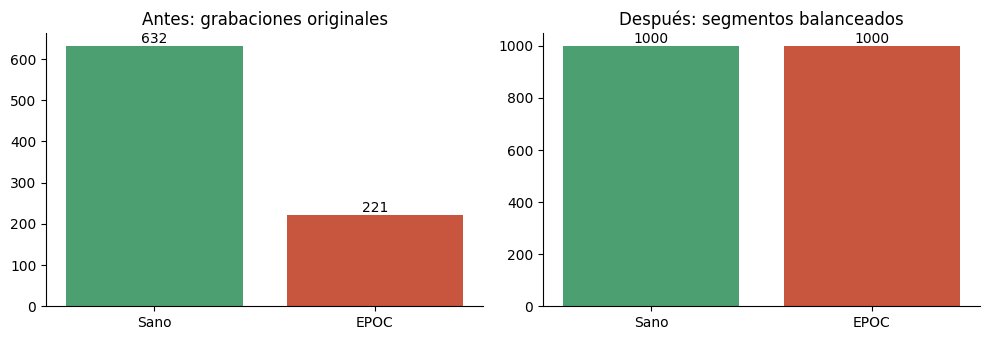

Estructura de carpetas generada:
  dataset_balanceado/test/epoc/  ->  177 audios
  dataset_balanceado/test/sano/  ->  192 audios
  dataset_balanceado/train/epoc/  ->  823 audios
  dataset_balanceado/train/sano/  ->  808 audios


In [ ]:
# Antes vs después del balanceo
antes = df.label.map({0: 'Sano', 1: 'EPOC'}).value_counts()[['Sano', 'EPOC']]
despues = meta.label.map({0: 'Sano', 1: 'EPOC'}).value_counts()[['Sano', 'EPOC']]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, v, tit in [(ax[0], antes, 'Antes: grabaciones originales'), (ax[1], despues, 'Después: segmentos balanceados')]:
    a.bar(v.index, v.values, color=['#4C9F70', '#C8553D'])
    for i, val in enumerate(v.values):
        a.text(i, val, f"{val}", ha='center', va='bottom')
    a.set_title(tit); a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

print("Estructura de carpetas generada:")
for d in sorted(DEST.glob('*/*')):
    print(f"  dataset_balanceado/{d.parent.name}/{d.name}/  ->  {len(list(d.glob('*.wav')))} audios")

## 11. Limpieza del audio y control de fuga del ambiente
Para que el modelo no use el ambiente ni el micrófono:
1. Se reduce el ruido de fondo de cada grabación (`noisereduce`).
2. Se conservan **solo los tramos de tos**, concatenados hasta 5 s, con volumen normalizado.
3. **Control:** se extraen los mismos rasgos del **fondo limpio sin tos**. Si ese control da AUC ≈ 0.5, la fuga quedó cerrada y lo que obtenga el modelo con la tos se debe a la tos.

In [ ]:
!pip -q install noisereduce
import noisereduce as nr

def cargar(row):
    x, _ = librosa.load(str(row.path), sr=SR, mono=True)
    return sosfiltfilt(SOS, x)

def normalizar(s):
    s = s - s.mean()
    return (s / (np.max(np.abs(s)) + 1e-9) * 0.9).astype(np.float32)

def concat_toses(x, segs, L=5.0):
    partes = [x[int(a*SR):int(b*SR)] for a, b in segs]
    s = np.concatenate(partes) if partes else x
    return normalizar(np.resize(s, int(L*SR)))        # repite si es más corto que L

def fondo_de(x, segs):
    m = np.ones(len(x), bool)
    for a, b in segs:
        m[max(0, int((a-0.1)*SR)):int((b+0.1)*SR)] = False
    return x[m] if m.any() else x

limpio = [nr.reduce_noise(y=cargar(r), sr=SR, stationary=True) for _, r in tqdm(df.iterrows(), total=len(df), desc="Limpiando")]

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Rasgos acústicos clásicos: MFCC + deltas, rasgos espectrales y duración de cada tos
def rasgos(x, segs):
    s = concat_toses(x, segs, 5.0)
    mf = librosa.feature.mfcc(y=s, sr=SR, n_mfcc=20); d = librosa.feature.delta(mf)
    esp = [librosa.feature.spectral_centroid(y=s, sr=SR), librosa.feature.spectral_bandwidth(y=s, sr=SR),
           librosa.feature.spectral_rolloff(y=s, sr=SR), librosa.feature.spectral_flatness(y=s),
           librosa.feature.zero_crossing_rate(s)]
    durs = [b - a for a, b in segs] or [0]
    return np.concatenate([mf.mean(1), mf.std(1), d.mean(1), d.std(1),
                           [f.mean() for f in esp], [f.std() for f in esp],
                           [np.mean(durs), np.std(durs)]])

NOMBRES = ([f"mfcc{i}_m" for i in range(20)] + [f"mfcc{i}_s" for i in range(20)] +
           [f"dmfcc{i}_m" for i in range(20)] + [f"dmfcc{i}_s" for i in range(20)] +
           [f"{n}_m" for n in ['centroide', 'ancho', 'rolloff', 'planitud', 'zcr']] +
           [f"{n}_s" for n in ['centroide', 'ancho', 'rolloff', 'planitud', 'zcr']] + ['dur_m', 'dur_s'])

X_tos = np.stack([rasgos(x, r.segs) for x, (_, r) in tqdm(zip(limpio, df.iterrows()), total=len(df), desc="Rasgos tos")])
X_fondo = np.stack([rasgos(fondo_de(x, r.segs), [(0, 1)]) for x, (_, r) in tqdm(zip(limpio, df.iterrows()), total=len(df), desc="Rasgos fondo")])[:, :-2]
print(X_tos.shape, X_fondo.shape)

Rasgos fondo: 100%|██████████| 853/853 [01:05<00:00, 13.05it/s]

(853, 92) (853, 90)


## 12. Modelo final: rasgos clásicos de la tos + Random Forest
Se compara el modelo con su control y con una versión sin los rasgos de duración, para comprobar que no depende de un solo atributo.

                             modelo           AUC           IC95
Control: rasgos del fondo (sin tos) 0.554 ± 0.020 [0.533, 0.618]
     Modelo final: rasgos de la tos 0.670 ± 0.013 [0.632, 0.711]
          Modelo final sin duración 0.664 ± 0.015 [0.628, 0.707]


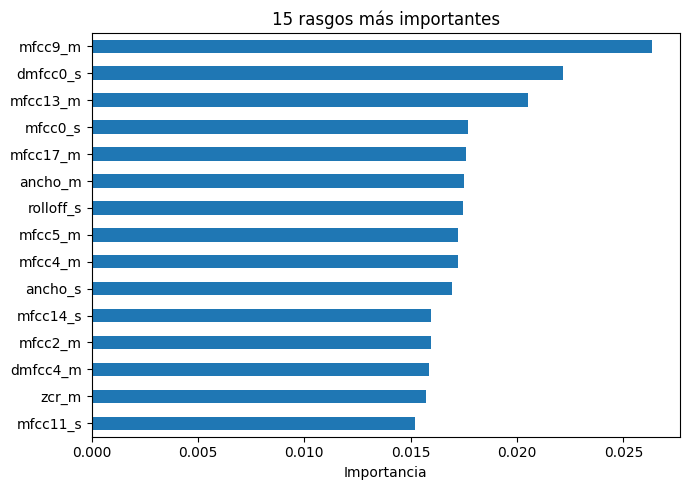

In [ ]:
rfm = lambda: RandomForestClassifier(500, class_weight='balanced', min_samples_leaf=3, random_state=0)

resultados = []
for nombre, X in [("Control: rasgos del fondo (sin tos)", X_fondo),
                  ("Modelo final: rasgos de la tos", X_tos),
                  ("Modelo final sin duración", X_tos[:, :-2])]:
    r_, rec0 = evaluar(rfm, X, y_rec, g_rec, df.rec_id.values, repeats=5)
    lo, hi = boot_ci(rec0.y.values, rec0.p.values)
    resultados.append(dict(modelo=nombre, AUC=f"{r_.auc_grab.mean():.3f} ± {r_.auc_grab.std():.3f}",
                           IC95=f"[{lo:.3f}, {hi:.3f}]"))
print(pd.DataFrame(resultados).to_string(index=False))

imp = pd.Series(rfm().fit(X_tos, y_rec).feature_importances_, index=NOMBRES).sort_values(ascending=False)
ax = imp.head(15)[::-1].plot.barh(figsize=(7, 5), title="15 rasgos más importantes")
ax.set_xlabel("Importancia"); plt.tight_layout(); plt.show()

## 13. Métricas de tamizaje
En tamizaje se prioriza la **sensibilidad**. El umbral se elige para alcanzar ~85 % de sensibilidad usando **solo los datos de entrenamiento** de cada fold y se aplica a los de prueba. Con la sensibilidad y la especificidad se calculan el VPP y el VPN para distintas prevalencias.

In [ ]:
from sklearn.metrics import roc_curve

def tamizaje_cv(mk, X, sens_obj=0.85, repeats=5):
    out = []
    for rep in range(repeats):
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=200 + rep).split(X, y_rec, g_rec):
            p_in = np.zeros(len(tr))
            for a, b in StratifiedGroupKFold(4, shuffle=True, random_state=rep).split(X[tr], y_rec[tr], g_rec[tr]):
                p_in[b] = mk().fit(X[tr][a], y_rec[tr][a]).predict_proba(X[tr][b])[:, 1]
            fpr, tpr, thr = roc_curve(y_rec[tr], p_in)
            u = thr[np.argmax(tpr >= sens_obj)]
            p = mk().fit(X[tr], y_rec[tr]).predict_proba(X[te])[:, 1]
            tn, fp, fn, tp = confusion_matrix(y_rec[te], (p >= u).astype(int), labels=[0, 1]).ravel()
            out.append((tp / (tp + fn), tn / (tn + fp)))
    return np.mean(out, 0)

se, es = tamizaje_cv(rfm, X_tos)
print(f"Sensibilidad = {se:.1%} | Especificidad = {es:.1%}\n")
filas = []
for nombre, prev in [("Dataset CC", 0.26), ("Fumadores > 40 años (aprox.)", 0.12), ("Población general > 40 años (aprox.)", 0.06)]:
    vpp = se*prev / (se*prev + (1-es)*(1-prev)); vpn = es*(1-prev) / (es*(1-prev) + (1-se)*prev)
    derivados = se*prev + (1-es)*(1-prev)
    filas.append(dict(escenario=nombre, prevalencia=f"{prev:.0%}", VPP=f"{vpp:.1%}", VPN=f"{vpn:.1%}",
                      derivados_a_espirometria=f"{derivados:.0%}"))
print(pd.DataFrame(filas).to_string(index=False))

Sensibilidad = 86.6% | Especificidad = 33.0%

                           escenario prevalencia   VPP   VPN derivados_a_espirometria
                          Dataset CC         26% 31.2% 87.5%                      72%
        Fumadores > 40 años (aprox.)         12% 15.0% 94.8%                      69%
Población general > 40 años (aprox.)          6%  7.6% 97.5%                      68%


## 14. Resumen de experimentos y conclusiones

| Experimento | AUC CV | Interpretación |
|---|---|---|
| Solo metadatos de grabación (duración, volumen, silencios) | ≈ 0.67 | Hay atajos de grabación en el dataset |
| YAMNet, grabación completa sin limpiar | ≈ 0.72 | Inflado: casi igual que solo metadatos |
| YAMNet, ventanas de tos de 1.5 s normalizadas | ≈ 0.53 | Sin la pista del ambiente, ventanas cortas no bastan |
| YAMNet, recorte de 5 s normalizado | ≈ 0.71 | Ruido de fondo y micrófono solos ya daban ≈ 0.67 |
| YAMNet, tos limpia concatenada | ≈ 0.63 | Control de fondo limpio ≈ 0.54: señal real pero baja |
| **Rasgos clásicos de la tos limpia + RF (modelo final)** | **≈ 0.67** | **Control ≈ 0.55: señal atribuible a la tos** |

*Valores de la ejecución del 15/10/2026; pueden variar ±0.01 al volver a ejecutar.*

**Sobre el balanceo:** los segmentos balanceados (sección 10), evaluados solos con YAMNet, dieron AUC ≈ 0.53, porque ventanas de 1.5 s no bastan cuando se elimina la pista del ambiente. Por eso el modelo final trabaja por grabación, con la tos limpia concatenada, y maneja el desbalance con pesos por clase.

**Conclusiones**
1. El dataset CC tiene **sesgo de grabación**: sin controles, los modelos aprenden el ambiente y el micrófono, y el AUC aparente (≈ 0.72–0.74) está inflado.
2. Tras limpiar el audio y verificar con controles, el sonido de la tos conserva una **señal real de EPOC** (AUC ≈ 0.67).
3. Para tamizaje, con sensibilidad ≈ 85 % la especificidad es baja (≈ 33 %): la tos **sola** no basta como prueba única de tamizaje.
4. Propuesta: usar la tos como **componente de un tamizaje híbrido** junto con un cuestionario de factores de riesgo (edad, tabaquismo, humo de leña, síntomas), con derivación a espirometría.

**Limitaciones:** la carpeta de cada audio se usó como identificador de participante; detección de toses por energía (aproximada); un solo dataset, sin validación externa en población peruana.

## Anexo: descargar el conjunto balanceado (opcional)

In [ ]:
# Descargar el conjunto balanceado como ZIP (opcional)
from google.colab import files
shutil.make_archive('/content/dataset_balanceado', 'zip', '/content/cc/dataset_balanceado')
files.download('/content/dataset_balanceado.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>